In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Veamos si nuestras librerias funcionan (Si aparece la gráfica es que el entorno esta listo jejeje)

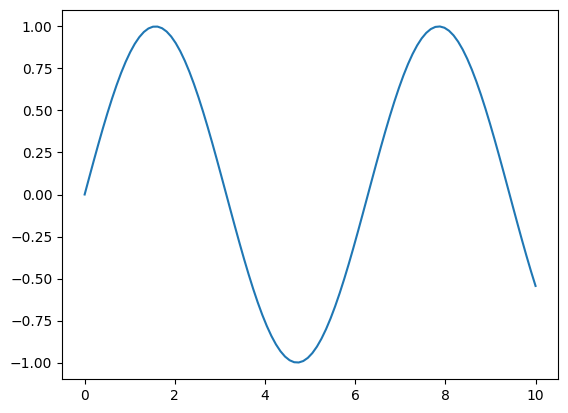

In [2]:
x = np.linspace(0,10,100)
y = np.sin(x)

plt.plot(x, y)
plt.show()

--- 

Una primera idea de simulación es tratar de simular rendimientos de una inversión, para ello primero debemos de entender que al invertir se pueden generar rendimientos positivos o negativos (pérdidas o ganancias), es por ello que si de simular se trata la variable aleatoria de la cual debemos hacer uso en primera instancia debera abarcar este tipo de comportamiento. 

En los cursos de probabilidad 1 se muestran distribuciones univariadas con estas características, las cuales podrían ser:
- Normal (Gaussiana)
- T de Student
- Cauchy (Caso especial de la T de student)
La más sencilla de entender y que más aplicaciones tiene en el mundo financiero es la normal, por lo que nuestra primera simulación consistirá en hacer uso de ella. 

In [3]:
# Primero establecemos una media (rendimiento esperado) y desviación estándar (volatilidad) para hacer uso de la normal
mu = 0.08 #Un rendimiento esperado anual de 8% 
vol = 0.15 #Volatilidad anual del 15% es decir, los rendimientos obtenidos se alejan del 8% en 15% anualmente
dias = 52*5 #Días bursátiles )aproximación)

#Convertimos rendimientos y volatilidad a escala diaria, y esto en que se basa?
mu_d = mu/dias
vol_d = vol/np.sqrt(dias)

Este último resultado esta basado en que hacer supuestos a una variable aleatoria anual, como suma de variables aleatorias diarias de la siguiente forma:
$$R_{anual} = \sum_1^{dias} R_i$$
Dónde cada $R_1, R_2, ...$ son una muestra aleatoria (v.a.i.i.d.) normales.
Así al calcular el rendimiento esperado anual se tiene:
$$ E [R_{anual}] = \sum_1^{dias} E[R_i]=\sum_1^{dias} E[R_1]= dias*E[R_1]$$
$$ \Longrightarrow \mu_a = dias * \mu_d \Longrightarrow \mu_d = \mu_a / dias$$
Y la varianza:
$$Var [R_{anual}] = \sum_1^{dias} Var[R_i]=\sum_1^{dias} Var[R_1]= dias*Var[R_1]$$
$$ \Longrightarrow \sigma_a^2 = dias * \sigma_d^2 \Longrightarrow \sigma_d = \sigma_a / \sqrt{dias}$$

Sin embargo justamente estos supuestos, sobre todo que sean independientes corresponde una fuerte crítica a esta forma de simular, para ello dará paso a otras formas de modelar este problema. 

Por ahora sigamos con esta forma de modelar el fenómeno.

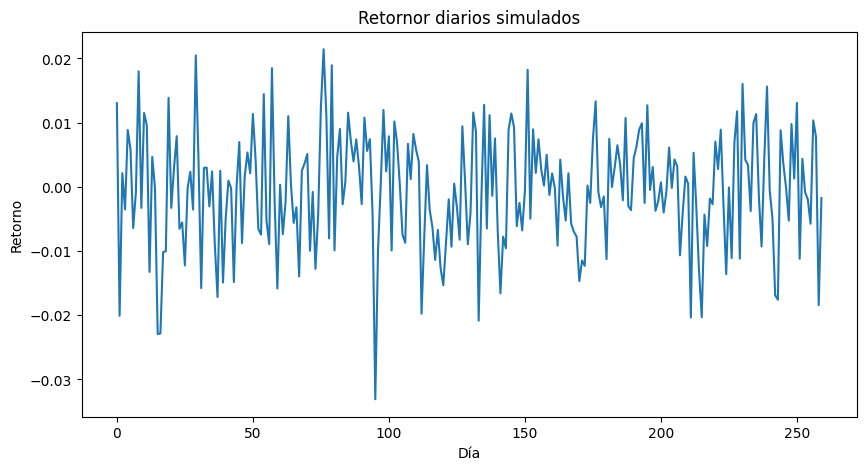

In [25]:
np.random.seed(187) #Fijamos una semilla para reproducibilidad (187)
# Generemos simulaciones de normales cn las características anteriores
retornos = np.random.normal(loc=mu_d, scale=vol_d, size=dias) #Simulamos los días con la esperanza diaria y volatilidad

#Graficamos los retornos 
plt.figure(figsize=(10,5)) #Creamos la figura, es el espacio donde va ir la gráfica con un tamaño de 10 ancho por 5 alto
plt.plot(retornos)

plt.title("Retornor diarios simulados")
plt.xlabel("Día")
plt.ylabel("Retorno")

plt.show()

Algunos días son positivos y algunos días son negativos los reotrnos obtenidos, esto representa un comportamiento aleatorio de los retornos y en general esta alrededor del 0.
Ahora bie si tuvieramos un activo el cuál estos fueran las ganancias o pérdidas que tuviera día con día, entonces la evolución de cada día sería la siguiente. Suponiendo un capital inicial de 100000

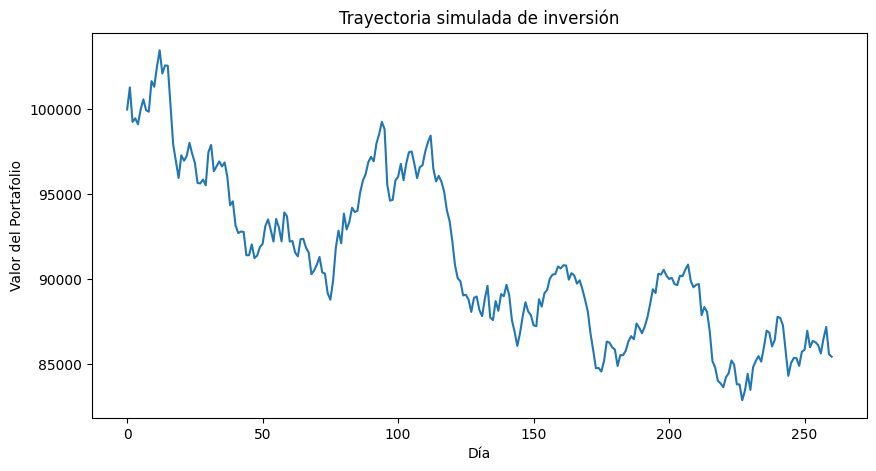

In [26]:
capini = 100000

trayectoria = [capini]

for r in retornos:
    nuevo_valor = trayectoria[-1]*(1+r)
    trayectoria.append(nuevo_valor)

plt.figure(figsize=(10,5)) #Creamos la figura, es el espacio donde va ir la gráfica con un tamaño de 10 ancho por 5 alto
plt.plot(trayectoria)

plt.title("Trayectoria simulada de inversión")
plt.xlabel("Día")
plt.ylabel("Valor del Portafolio")

plt.show()

En vez de sólo una trayectoria vamos a generar cientos o miles, así cada línea generada va a ser un posible futuro, veamos el posible futuro. 

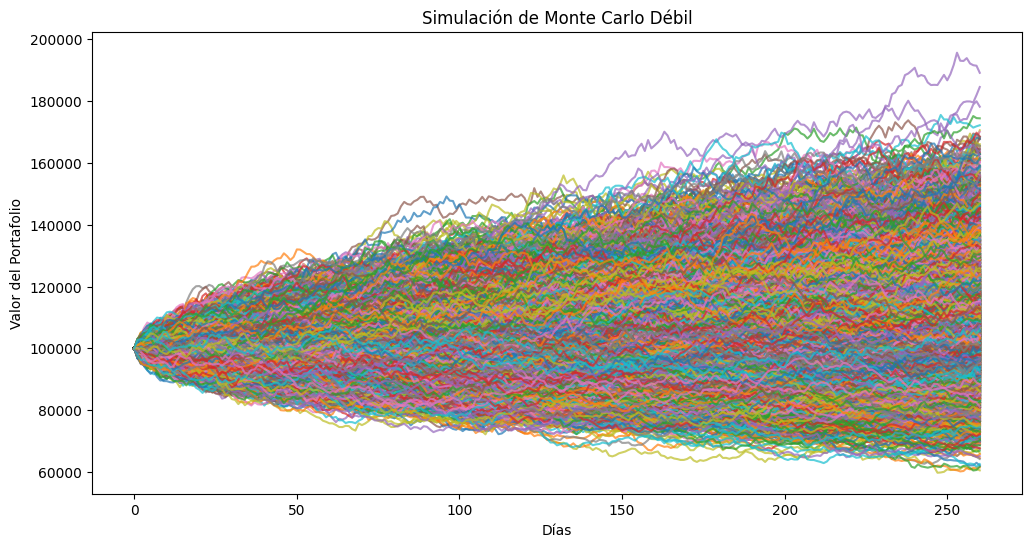

In [45]:
np.random.seed(123)
simulaciones = 10000

#Creamos la figura
plt.figure(figsize=(12,6))

ultimos_valores = []
for _ in range(simulaciones):
    retornos=np.random.normal(mu_d, vol_d, dias)
    trayectoria = [capini]

    for r in retornos:
        nuevo_valor = trayectoria[-1]*(1+r)
        trayectoria.append(nuevo_valor)
    plt.plot(trayectoria, alpha = 0.7) #El alpha hace líneas transparentes para mejorar la visibilidad
    ultimos_valores.append(trayectoria[-1])

plt.title("Simulación de Monte Carlo Débil")
plt.xlabel("Días")
plt.ylabel("Valor del Portafolio")

plt.show()

Con esto logramos capturar los posibles futuros, ahora tomemos los últimos valores o los valores donde termino nuestra inversión después de un año y hagamos inferencia sobre estos.

In [44]:
ultimos_valores = np.array(ultimos_valores)

#Estadísticas
promedio = np.mean(ultimos_valores)
mediana = np.median(ultimos_valores)

percentil_5 = np.percentile(ultimos_valores, 5)
percentil_95 = np.percentile(ultimos_valores, 95)

# Probabilidad de Pérdida
prob_perdida = np.mean(ultimos_valores < capini)

print(f"Promedio final: $ {promedio:,.2f}")
print(f"Mediana final: $ {mediana:,.2f}")

print(f"Percentil 5 (VaR 95): $ {percentil_5:,.2f}")
print(f"Percentil 95: $ {percentil_95:,.2f}")

print(f"Probabilidad de perder: {prob_perdida:,.2f}")



Promedio final: $ 108,328.15
Mediana final: $ 106,921.59
Percentil 5 (VaR 95): $ 83,857.45
Percentil 95: $ 137,688.45
Probabilidad de perder: 0.33


<function matplotlib.pyplot.show(close=None, block=None)>

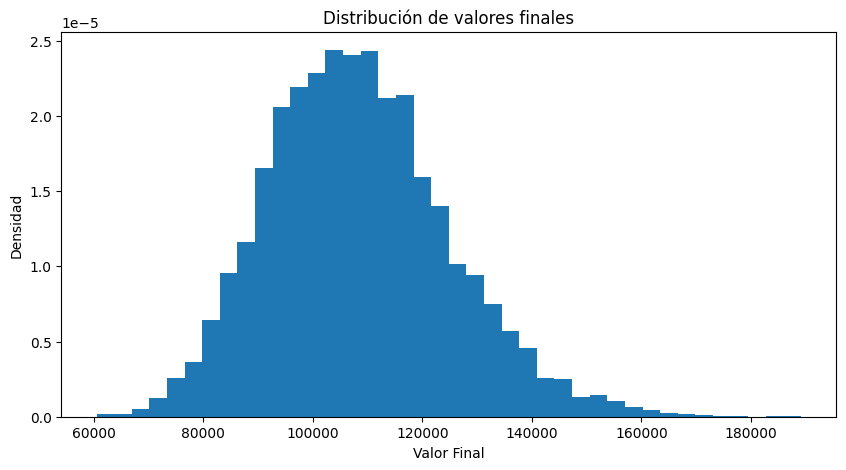

In [51]:
plt.figure(figsize=(10,5))

plt.hist(ultimos_valores, bins=40, density=True)

plt.title("Distribución de valores finales")
plt.xlabel("Valor Final")
plt.ylabel("Densidad")

plt.show

Así aunque el rendimiento esperado y el valor del portafolio en promedio son positivos, el histograma y la probabilidad de pérdida muestran que aún existe un riesgo considerable de perder en este tipo de inversión. Sin embargo esto no es más que una suposición de el rendimiento esperado (0.08) así como de la volatilidad (0.15) anuales.

¿Cómo sabemos quienes son estos rendimientos esperados, quien es la volatilidad anual o diaria?, pues este es el siguiente paso, hacer esto pero con datos reales.